# Main project: annealing, genetic search and ant colonies

Both original TSPLIB instances compare three annealing neighborhoods, four pure GA recipes, AS / ACS / ACS+2opt, NN+2opt, two memetic GA extensions and OR-Tools. Every fit is retained. Work caps and library wall-clock budgets have different meanings.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Permutation operators

In [2]:
from optimization_lab.routing import order_crossover,cycle_crossover,mutate,tour_length
rng=np.random.default_rng(0);a=rng.permutation(12);b=rng.permutation(12)
for child in [order_crossover(a,b,rng),cycle_crossover(a,b),mutate(a,rng,"insert")]:
    assert np.array_equal(np.sort(child),np.arange(12))
print("Every child is a complete permutation")

Every child is a complete permutation


## All runs and gaps

In [3]:
fits=pd.read_csv(ROOT/"docs/routing_fits.csv")
assert len(fits)==84
fits.groupby(["instance","method"]).gap_to_published_optimum_percent.agg(["mean","std","min","max"])

mean        std         min         max
instance method                                                           
berlin52 acs                   0.932555   1.558173    0.000000    2.731371
         acs_2opt              0.000000   0.000000    0.000000    0.000000
         as                    1.577831   0.045931    1.524794    1.604349
         ga_cx_reverse         9.511182   2.686865    7.597454   12.582869
         ga_cx_reverse_2opt    0.000000   0.000000    0.000000    0.000000
         ga_cx_swap           34.442677   4.615177   29.474940   38.597189
         ga_ox_reverse         6.801909   4.379172    2.996553   11.588438
         ga_ox_reverse_2opt    0.000000   0.000000    0.000000    0.000000
         ga_ox_swap           25.492796   6.782177   18.390347   31.901352
         nn_2opt               6.448334   2.059402    4.070538    7.663750
         ortools_gls           2.298241   2.009717    0.000000    3.725802
         sa_insert             7.685848   4.988347    4.150093   13.391673
         sa_reverse            1.900468   1.729197    0.000000    3.381066
         sa_swap              11.292319   1.592489    9.533280   12.635906
ch150    acs                   3.783701   2.069092    2.068015    6.081495
         acs_2opt              1.429739   0.892871    0.796569    2.450980
         as                   10.186887   2.150508    7.705270   11.504289
         ga_cx_reverse       138.311887  15.091507  126.960784  155.438113
         ga_cx_reverse_2opt    2.629698   0.431739    2.144608    2.971814
         ga_cx_swap          131.413399  13.335060  120.542279  146.292892
         ga_ox_reverse        37.418301   2.483807   35.232843   40.119485
         ga_ox_reverse_2opt    1.919935   0.031888    1.884191    1.945466
         ga_ox_swap          100.188930  11.100630   92.218137  112.867647
         nn_2opt               4.079861   0.476932    3.630515    4.580270
         ortools_gls           2.262051   0.197565    2.098652    2.481618
         sa_insert            13.613154   7.845775    8.961397   22.671569
         sa_reverse            9.865196   1.358703    8.961397   11.427696
         sa_swap              13.613154   7.845775    8.961397   22.671569

## Measured comparison

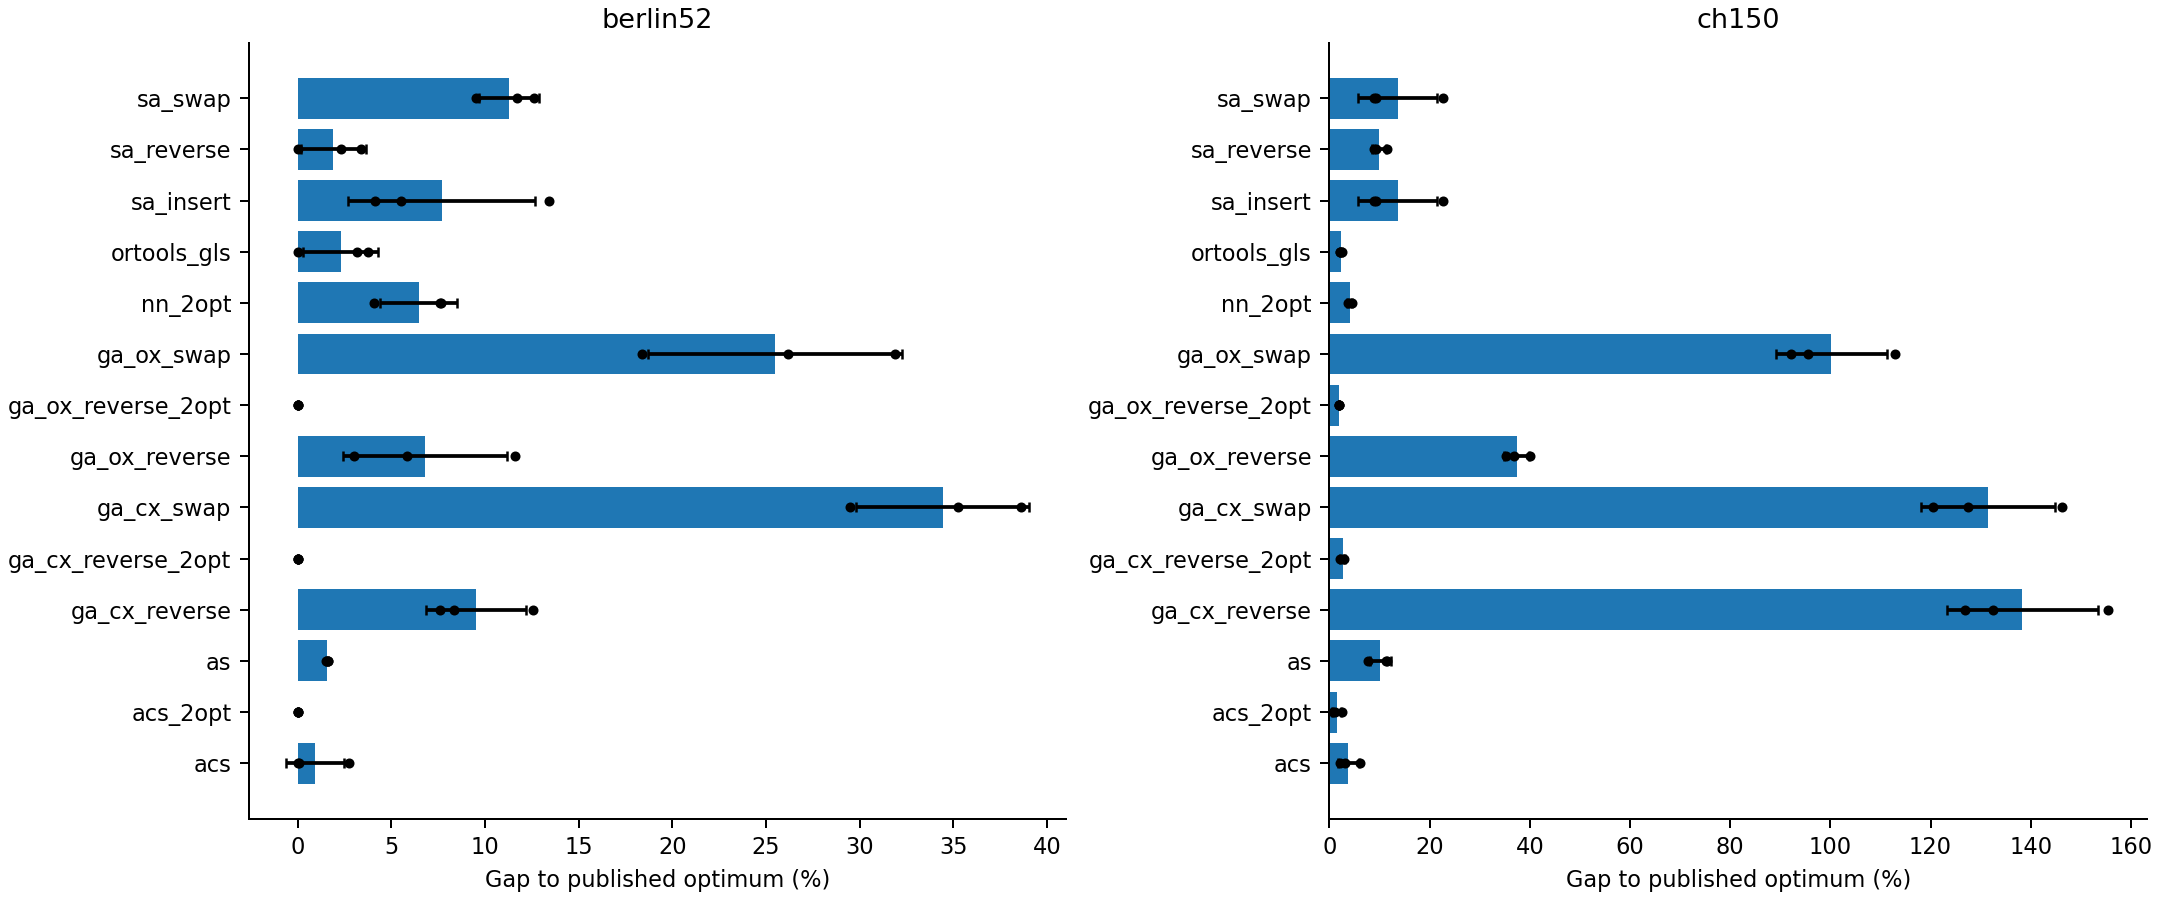

In [4]:
figure("routing_comparison")

## Fixed-seed route gallery

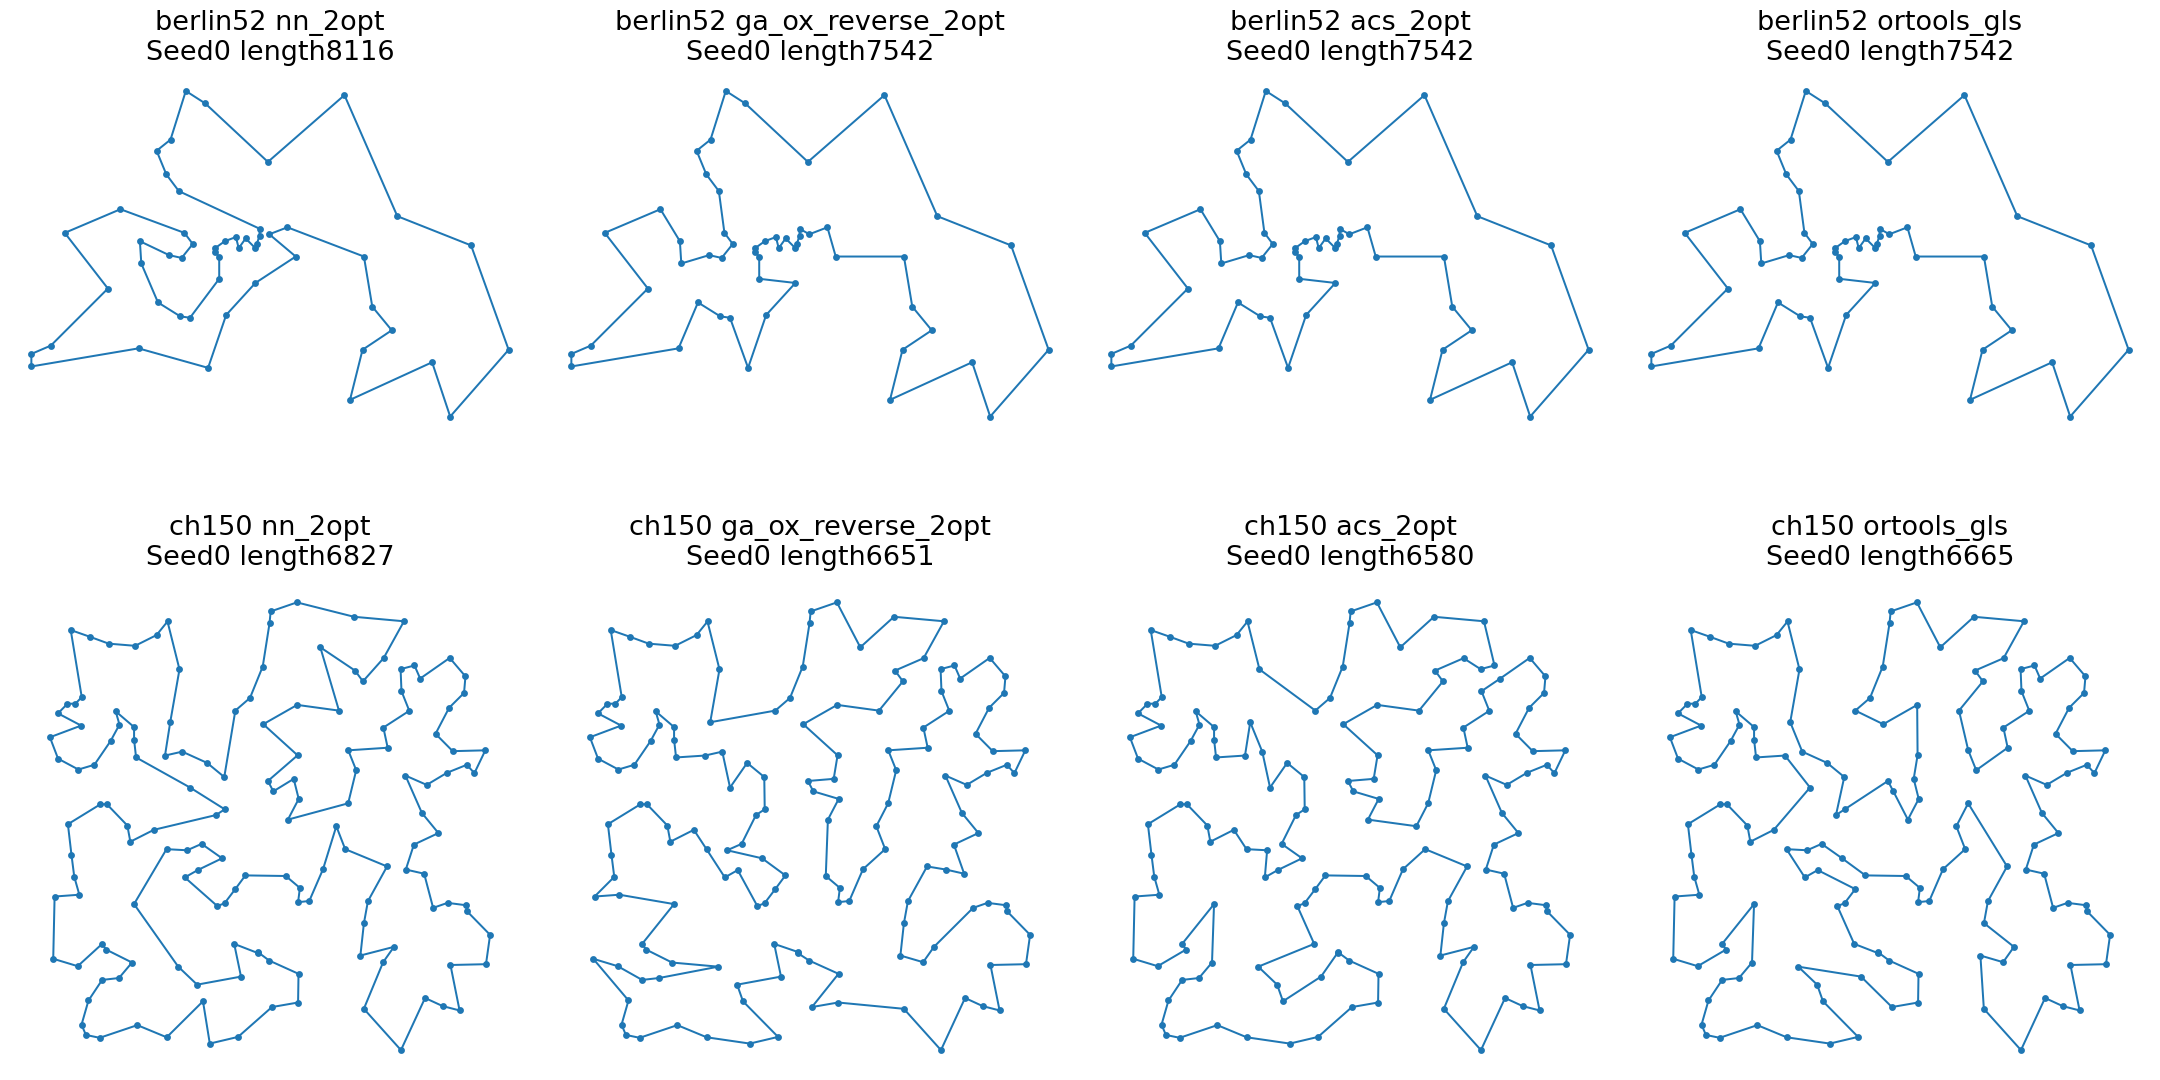

In [5]:
figure("routing_fixed_seed_tours")

## Convergence within counted work

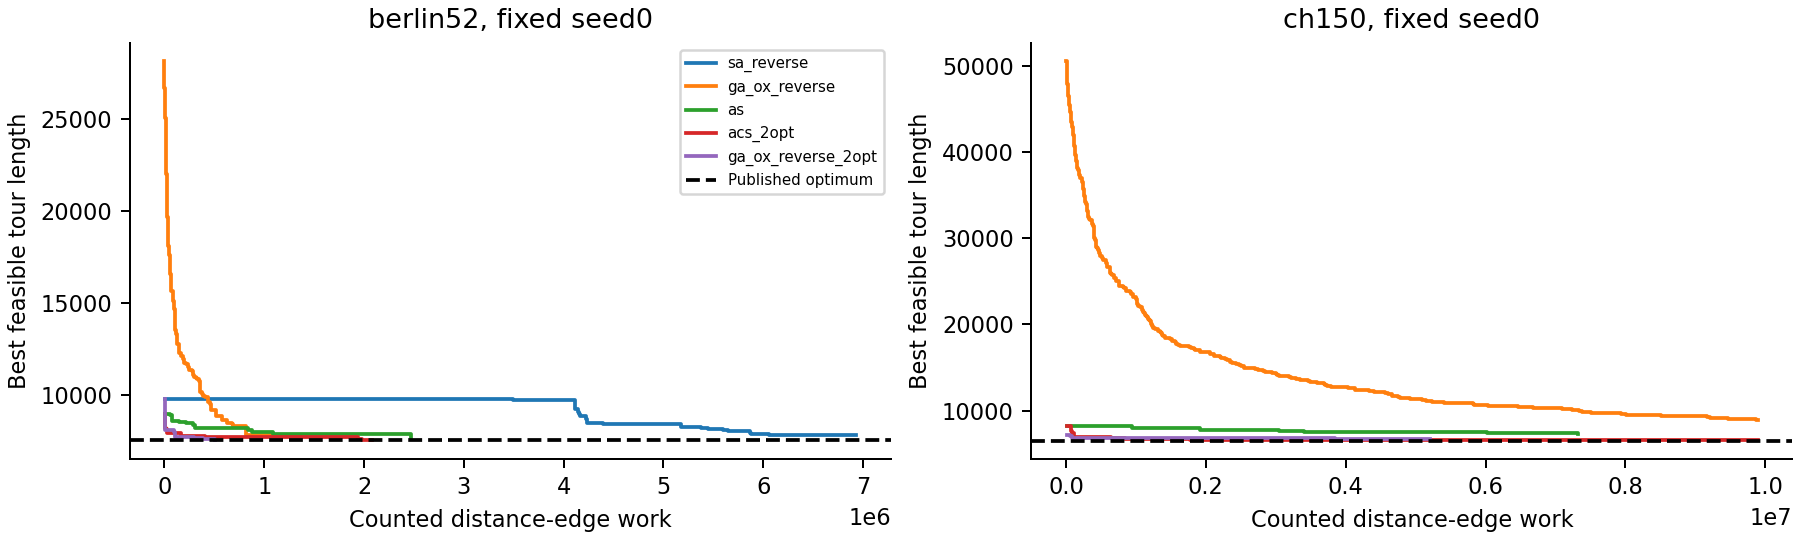

In [6]:
figure("routing_convergence")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.